<a href="https://colab.research.google.com/github/mildrerthcamartinezl-afk/PROYECTO-BIT-MILCA/blob/main/Entegable_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
TALLER PRÁCTICO – APRENDIZAJE  NO SUPERVISADO
Entrega: Octubre 23
@everyone
Instrucciones
Trabaja sobre el dataset suministrado y desarrolla un análisis completo que incluya las siguientes etapas:
df = https://www.kaggle.com/datasets/tamber/steam-video-games

Exploración de los datos
Realiza un análisis exploratorio del conjunto de datos que incluya:
    • Dimensiones del dataset.
    • Tipos de variables.
    • Valores nulos.
    • Registros duplicados.
    • Estadísticos descriptivos.
    • Visualizaciones que permitan comprender la información.

Preparación de los datos
Realiza el preprocesamiento necesario para aplicar técnicas de clustering.
Debes justificar cada decisión tomada.

Modelado
Implementa un algoritmo de clustering, por ejemplo:
    • K-Means
    • DBSCAN
    • Clustering Jerárquico
Justifica la elección de los algoritmos utilizados.

Interpretación de los clusters
Describe cada uno de los grupos encontrados.
Puedes responder preguntas como:
    • Qué caracteriza a los usuarios de este grupo?
    • Son jugadores ocasionales o frecuentes?
    • Presentan comportamientos similares de compra?
    • Qué diferencias existen entre los clusters?
Asigna un nombre representativo a cada segmento.
Ejemplo:
    • Jugadores Casual
    • Coleccionistas
    • Usuarios Muy Activos
    • Compradores Frecuentes

Recomendaciones de negocio
Con base en los segmentos encontrados, responde:
    • Qué estrategia de marketing implementarías para cada grupo?
    • Qué tipo de promociones recibiría cada segmento?
    • Qué usuarios priorizarías para campañas de fidelización?
Qué información adicional sería útil para mejorar la segmentación?
Steam Video Games
Recommend video games from 200k steam user interactions.
Imagen

In [6]:
import pandas as pd

df = pd.read_csv(
    "steam-200k.csv",
    header=None
)

df.head()

,0,1,2,3,4
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


In [7]:
df.columns = [
    'user_id',
    'game',
    'behavior',
    'value',
    'extra'
]

df.head()

,user_id,game,behavior,value,extra
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


In [10]:
#Exploración

print("Dimensiones:")
print(df.shape)

print("\nInformación:")
df.info()

Dimensiones:
(200000, 5)

Información:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   user_id   200000 non-null  int64  
 1   game      200000 non-null  object 
 2   behavior  200000 non-null  object 
 3   value     200000 non-null  float64
 4   extra     200000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [12]:
df.isnull().sum()

,0
user_id,0
game,0
behavior,0
value,0
extra,0


In [13]:
df.duplicated().sum()

np.int64(707)

In [17]:
df = df.drop_duplicates()

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.shape

(199293, 5)

In [22]:
df.describe()

,user_id,value,extra
count,1.992930e+05,199293.000000,199293.0
mean,1.037181e+08,17.934247,0.0
std,7.212048e+07,138.297952,0.0
min,5.250000e+03,0.100000,0.0
25%,4.738430e+07,1.000000,0.0
50%,8.691201e+07,1.000000,0.0
75%,1.542309e+08,1.400000,0.0
max,3.099031e+08,11754.000000,0.0


In [34]:
df = df.drop(columns=['extra'], errors='ignore')

In [35]:
df.columns

Index(['user_id', 'game', 'behavior', 'value'], dtype='object')

In [38]:
df.shape

(199293, 4)

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

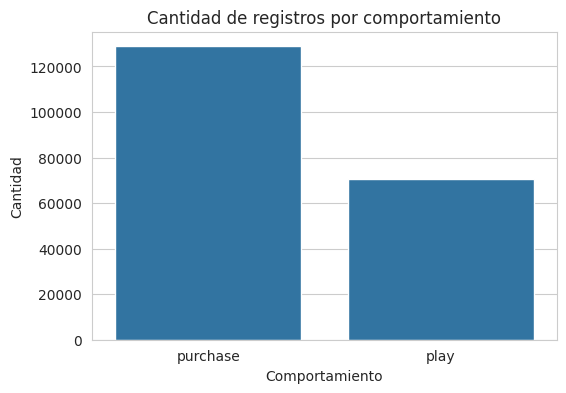

In [37]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='behavior')

plt.title('Cantidad de registros por comportamiento')
plt.xlabel('Comportamiento')
plt.ylabel('Cantidad')

plt.show()

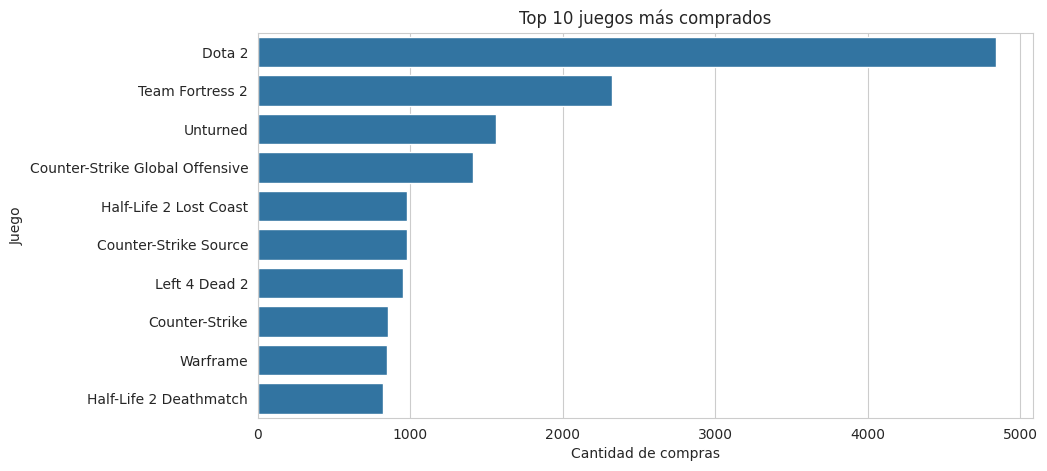

In [39]:
top_purchase = (
    df[df['behavior'] == 'purchase']['game']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_purchase.values,
    y=top_purchase.index
)

plt.title('Top 10 juegos más comprados')
plt.xlabel('Cantidad de compras')
plt.ylabel('Juego')

plt.show()

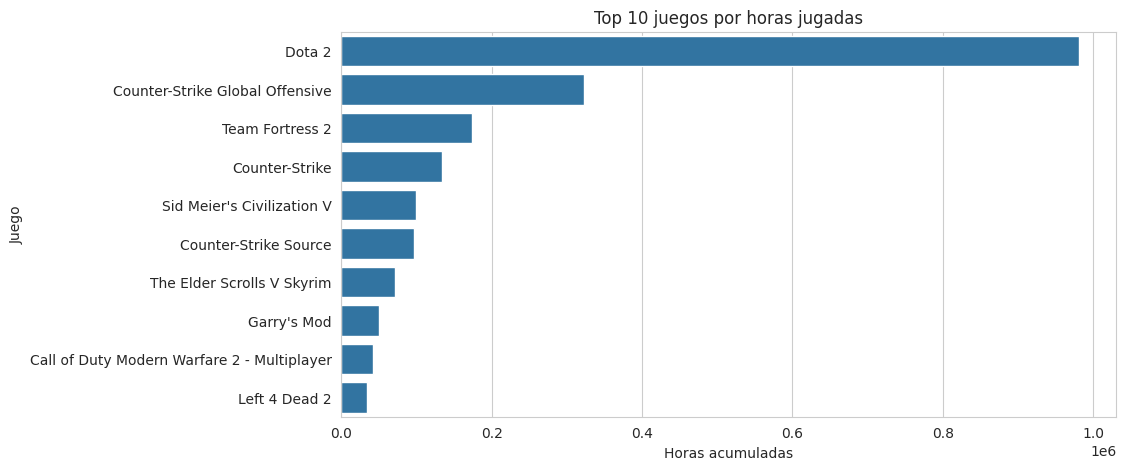

In [40]:
play_df = df[df['behavior'] == 'play']

top_hours = (
    play_df.groupby('game')['value']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_hours.values,
    y=top_hours.index
)

plt.title('Top 10 juegos por horas jugadas')
plt.xlabel('Horas acumuladas')
plt.ylabel('Juego')

plt.show()

Con el fin de aplicar técnicas de clustering, fue necesario realizar un proceso de preprocesamiento sobre el conjunto de datos para garantizar que la información fuera adecuada para el análisis.


- identificacion de datos y eliminacion de duplicados
- tambien de eliminaron datos irrelevantes
- se cobstuyeron variables:
num_purchases: cantidad de compras realizadas por cada usuario.
hours_played: total de horas jugadas por cada usuario.
num_games: cantidad de videojuegos diferentes adquiridos por cada usuario.

permiten caracterizar el comportamiento de los usuarios en términos de actividad, compromiso con la plataforma y hábitos de compra, para la segmentación.

In [ ]:
#Realiza el preprocesamiento necesario para aplicar técnicas de clustering. Debes justificar cada decisión tomada.

In [45]:
purchases = (
    df[df['behavior']=='purchase']
    .groupby('user_id')
    .size()
)
purchases.head()
print(purchases.head())

user_id
5250      21
76767     36
86540     82
103360    10
144736     8
dtype: int64


In [46]:
purchases.shape

(12393,)

In [47]:
hours_played = (
    df[df['behavior']=='play']
    .groupby('user_id')['value']
    .sum()
)

hours_played.head()

,value
user_id,
5250,225.5
76767,1227.0
86540,255.0
144736,0.1
181212,2.2


In [48]:
games_owned = (
    df[df['behavior']=='purchase']
    .groupby('user_id')['game']
    .nunique()
)

games_owned.head()

,game
user_id,
5250,21
76767,36
86540,82
103360,10
144736,8


In [49]:
users = pd.concat(
    [purchases, hours_played, games_owned],
    axis=1
)

users.columns = [
    'num_purchases',
    'hours_played',
    'num_games'
]

users.fillna(0, inplace=True)

users.head()

,num_purchases,hours_played,num_games
user_id,,,
5250,21,225.5,21
76767,36,1227.0,36
86540,82,255.0,82
103360,10,0.0,10
144736,8,0.1,8


In [50]:
from sklearn.preprocessing import StandardScaler

In [51]:
scaler = StandardScaler()

X = scaler.fit_transform(users)

In [52]:
X[:5]

array([[ 0.29765333, -0.06906901,  0.29765333],
       [ 0.71859428,  1.24827824,  0.71859428],
       [ 2.00947985, -0.03026547,  2.00947985],
       [-0.01103669, -0.36568589, -0.01103669],
       [-0.06716215, -0.36555435, -0.06716215]])

Implementa un algoritmo de clustering (K-Means, DBSCAN o Clustering Jerárquico). Justifica la elección.

In [54]:
from sklearn.cluster import KMeans

inercia = []

for k in range(2,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    inercia.append(kmeans.inertia_)

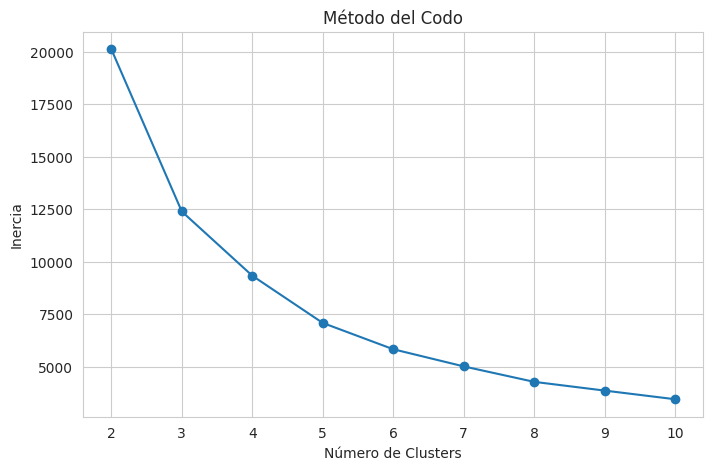

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    inercia,
    marker='o'
)

plt.title('Método del Codo')
plt.xlabel('Número de Clusters')
plt.ylabel('Inercia')

plt.show()

In [56]:
k = 4
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

users['cluster'] = kmeans.fit_predict(X)

In [57]:
users.head()

,num_purchases,hours_played,num_games,cluster
user_id,,,,
5250,21,225.5,21,1
76767,36,1227.0,36,3
86540,82,255.0,82,0
103360,10,0.0,10,1
144736,8,0.1,8,1


In [60]:
from sklearn.metrics import silhouette_score


In [61]:
score = silhouette_score(X, users['cluster'])

print(score)

0.8325466680852207


In [62]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X, users['cluster'])

print("Silhouette Score:", score)

Silhouette Score: 0.8325466680852207


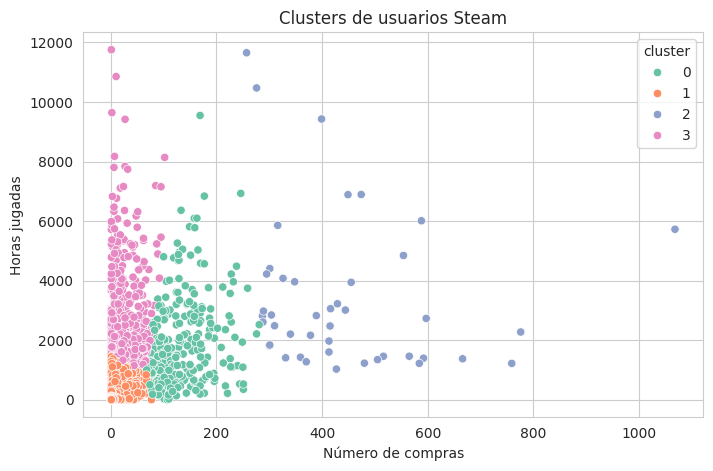

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=users,
    x='num_purchases',
    y='hours_played',
    hue='cluster',
    palette='Set2'
)

plt.title('Clusters de usuarios Steam')
plt.xlabel('Número de compras')
plt.ylabel('Horas jugadas')

plt.show()

 se seleccionó el algoritmo K-Means, debido a que permite identificar grupos de usuarios con características similares a partir de variables numéricas.

Con el objetivo de determinar el número adecuado de clusters, se aplicó el método del codo, evaluando valores de k entre 2 y 10. La gráfica mostró una disminución significativa de la inercia hasta k=4, a partir del cual las mejoras fueron menores, por lo que se seleccionaron cuatro clusters.

Luego las variables estandarizadas: número de compras, horas jugadas y cantidad de juegos adquiridos.

In [65]:
cluster_profile = users.groupby('cluster').mean()

cluster_profile


,num_purchases,hours_played,num_games
cluster,,,
0,127.626198,1770.145048,127.626198
1,4.811901,114.177540,4.811901
2,439.750000,3389.434091,439.750000
3,25.586022,2565.672939,25.586022


CLUSTER 0= Compradores Frecuentes

Promedio de 127.63 compras.
Promedio de 127.63 juegos.
Más de 1.700 horas jugadas.

Compradores frecuentes  y mantienen una actividad importante dentro de Steam

CLUSTER 1 = Jugadores Casual
Promedio de 4.81 compras.
Promedio de 4.81 juegos.
Aproximadamente 114 horas jugadas.

Compran pocos videojuegos y dedican un tiempo limitado al juego.

Cluster 2= Coleccionistas Premium

Promedio de 439.75 compras.
Promedio de 439.75 juegos.
Más de 3.300 horas jugada

grupo más activo y con mayor capacidad de compra. Poseen enormes bibliotecas de juegos y acumulan miles de horas de uso.

Cluster 3= Jugadores Muy Activos

Promedio de 25.59 compras.
Promedio de 25.59 juegos.
Más de 2.500 horas jugadas.

no poseen una gran cantidad de juegos, invierten una enorme cantidad de tiempo en los videojuegos que tienen.

Las principales diferencias entre los segmentos se encuentran en la cantidad de videojuegos adquiridos y en las horas jugadas. Mientras que los usuarios del Cluster 1 presentan una baja actividad y pocas compras, los usuarios del Cluster 2 muestran un nivel excepcionalmente alto de participación y consumo. Los Clusters 0 y 3 representan perfiles intermedios, diferenciándose porque uno se caracteriza por realizar numerosas compras y el otro por dedicar más horas de juego a una cantidad menor de títulos.




Para llevar a cabo una estrategia de marketing suguiero una por cada segmento que presentan caracteristicas especificas

Segmento 1: Jugadores Casual (cluster 1)
Características
Realizan pocas compras.
Tienen pocos videojuegos.
Registran pocas horas de juego.

Estrategia de marketing

- Implementar campañas de activación mediante correos personalizados, recomendaciones de juegos populares y eventos especiales para aumentar su participación en la plataforma.

- Promociones sugeridas
Descuentos de bienvenida.
Juegos gratuitos por tiempo limitado.
Cupones para primeras compras.

Objetivo

Incrementar la frecuencia de compra y el tiempo de permanencia en la plataforma.

Segmento 2: Jugadores Muy Activos (Cluster 3)
Características
Juegan muchas horas.
Mantienen una actividad constante.
Aprovechan intensamente los juegos que poseen.
Estrategia de marketing

Ofrecer contenido exclusivo y recompensas por fidelidad para mantener su nivel de participación.

Promociones sugeridas
Acceso anticipado a nuevos lanzamientos.
DLC gratuitos o con descuento.
Programas de puntos y recompensas.
Objetivo

Retener usuarios altamente comprometidos y evitar su migración a otras plataformas.

Segmento 3: Compradores Frecuentes (Cluster 0)
Características
Poseen grandes bibliotecas de juegos.
Compran con frecuencia.
Presentan altos niveles de actividad.
Estrategia de marketing

Promover juegos relacionados con sus intereses mediante sistemas de recomendación personalizados.

Promociones sugeridas
Bundles de videojuegos.
Descuentos por compras múltiples.
Suscripciones premium.
Objetivo

Incrementar el valor promedio de compra por usuario.

Segmento 4: Coleccionistas Premium (Cluster 2)
Características
Son los usuarios con más compras.
Poseen bibliotecas extremadamente grandes.
Acumulan miles de horas de juego.
Estrategia de marketing

Implementar programas VIP y beneficios exclusivos para usuarios de alto valor.

Promociones sugeridas
Acceso exclusivo a contenido especial.
Ediciones de colección.
Beneficios premium permanentes.
Objetivo

Conservar a los usuarios más rentables de la plataforma.

¿Qué usuarios deberían priorizarse para fidelización?

Los usuarios que deberían recibir la mayor atención son:

Cluster 2: Coleccionistas Premium

Porque:

Generan la mayor cantidad de compras.
Presentan el mayor compromiso con la plataforma.
Representan los clientes de mayor valor.
Cluster 3: Jugadores Muy Activos

Porque:

Dedican miles de horas a los videojuegos.
Son usuarios altamente comprometidos.
Tienen gran potencial para seguir comprando contenido adicional.




¿Qué información adicional sería útil para mejorar la segmentación?

La calidad de la segmentación podría mejorar incorporando variables adicionales como:

Edad del usuario.
País o región.
Género preferido de videojuegos.
Fecha de cada compra.
Valor monetario gastado.
Frecuencia de conexión.
Participación en eventos de Steam.
Interacción con promociones o descuentos.
Tiempo desde la última compra.

Estas variables permitirían construir perfiles más completos y generar estrategias de marketing más personalizadas.


